# 03 - Benchmark com a Biblioteca DeepOD

Comparação de modelos modernos de detecção profunda de anomalias com o nosso MLP Autoencoder, sob o mesmo protocolo experimental do projeto.

### Pergunta
Algum desses modelos detecta a **microtrinca na pista externa do Rolamento 1 (por volta do arquivo 532)** com **menor taxa de falso alarme** que o nosso Autoencoder?

### Modelos comparados
| Modelo | Origem | Entrada | Ideia |
| :--- | :--- | :--- | :--- |
| **MLP Autoencoder** (referência) | `03_modeling.ipynb` | 1 arquivo (`L=1`) | Erro de reconstrução (MSE) |
| **Deep SVDD** | `deepod` | 1 arquivo (`L=1`) | Distância ao centro de uma hiperesfera no espaço latente |
| **DIF** (*Deep Isolation Forest*) | `deepod` | 1 arquivo (`L=1`) | Isolation Forest sobre projeções de redes neurais aleatórias |
| **TranAD** | `deepod` | janela de 5 arquivos (`L=5`) | Transformer com reconstrução em 2 fases |

## Importando Bibliotecas e Carregando os Dados

In [1]:
import io
import warnings
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

from deepod.models.tabular import DeepSVDD, DeepIsolationForest
from deepod.models.tabular import dif as dif_modulo
from deepod.models.time_series import TranAD
from deepod.models.time_series import tranad as tranad_modulo

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
CAMINHO_ATUAL = Path(".").resolve()
if CAMINHO_ATUAL.name == "notebooks":
    RAIZ_PROJETO = CAMINHO_ATUAL.parent
else:
    RAIZ_PROJETO = CAMINHO_ATUAL

PASTA_PROCESSED = RAIZ_PROJETO / "data" / "processed"
PASTA_REPORTS = RAIZ_PROJETO / "reports"
PASTA_MODELS = RAIZ_PROJETO / "notebooks" / "models" / "deepod_benchmark"

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
SEEDS = [42, 123, 456]
JANELA_SUSTENTADA = 5
FIM_DA_VIDA_IDX = 981

df = pd.read_csv(PASTA_PROCESSED / "2nd_test_features.csv")
print(f"Dataset carregado: {df.shape[0]} linhas e {df.shape[1]} colunas  |  Dispositivo: {DISPOSITIVO}")

Dataset carregado: 984 linhas e 47 colunas  |  Dispositivo: cuda


## 1. Divisão Temporal e Padronização (sem Data Leakage)

In [3]:
df_ativo = df[df["idx"] <= 981].copy()
colunas_features = [c for c in df_ativo.columns if c.startswith("b1_")]

df_train = df_ativo[(df_ativo["idx"] >= 0)   & (df_ativo["idx"] <= 400)].copy()
df_val   = df_ativo[(df_ativo["idx"] >= 451) & (df_ativo["idx"] <= 530)].copy()
df_test  = df_ativo[(df_ativo["idx"] >= 531) & (df_ativo["idx"] <= 981)].copy()

scaler = StandardScaler()
X_train = scaler.fit_transform(df_train[colunas_features]).astype(np.float32)
X_val   = scaler.transform(df_val[colunas_features]).astype(np.float32)
X_test  = scaler.transform(df_test[colunas_features]).astype(np.float32)

print(f"Treino (Saudável):    {X_train.shape[0]} amostras x {X_train.shape[1]} features")
print(f"Validação (Saudável): {X_val.shape[0]} amostras  x {X_val.shape[1]} features")
print(f"Teste (Falha):        {X_test.shape[0]} amostras x {X_test.shape[1]} features")

Treino (Saudável):    401 amostras x 11 features
Validação (Saudável): 80 amostras  x 11 features
Teste (Falha):        451 amostras x 11 features


## 2. Ajustes de Compatibilidade da Biblioteca `deepod`

In [ ]:
def _ignorar_is_causal(forward_original):
    def forward(self, *args, **kwargs):
        kwargs = {k: v for k, v in kwargs.items() if not k.endswith("is_causal")}
        return forward_original(self, *args, **kwargs)
    return forward

for camada in (tranad_modulo.TransformerEncoderLayer, tranad_modulo.TransformerDecoderLayer):
    camada.forward = _ignorar_is_causal(camada.forward)


class DIFSemVazamento(DeepIsolationForest):
    _scalers_treino = None

    def decision_function(self, X):
        primeira_chamada = self._scalers_treino is None
        if primeira_chamada:
            self._scalers_treino = []

        scores = np.zeros((self.n_ensemble, X.shape[0]))
        for i in range(self.n_ensemble):
            reduzido = self.net_lst[i](torch.from_numpy(X).float()).data.numpy()
            if primeira_chamada:
                self._scalers_treino.append(StandardScaler().fit(reduzido))
            reduzido = np.tanh(self._scalers_treino[i].transform(reduzido))
            scores[i] = dif_modulo.cal_score(reduzido, self.iForest_lst[i])
        return scores.mean(axis=0)

## 3. Definição dos Modelos

In [ ]:
class MLPAutoencoder(nn.Module):
    def __init__(self, input_dim=11, latent_dim=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.GELU(),
            nn.Linear(32, 16),
            nn.GELU(),
            nn.Linear(16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.GELU(),
            nn.Linear(16, 32),
            nn.GELU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def treinar_pontuar_autoencoder(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    modelo = MLPAutoencoder(input_dim=X_train.shape[1], latent_dim=4)
    criterio = nn.MSELoss()
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train)), batch_size=32, shuffle=True)

    for _ in range(150):
        modelo.train()
        for (lote,) in loader:
            otimizador.zero_grad()
            criterio(modelo(lote), lote).backward()
            otimizador.step()

    modelo.eval()
    with torch.no_grad():
        return [
            np.mean((X - modelo(torch.from_numpy(X)).numpy()) ** 2, axis=1)
            for X in (X_train, X_val, X_test)
        ]


def pontuar_deepod(modelo, janela=1):
    with redirect_stdout(io.StringIO()):   
        modelo.fit(X_train)
    return [modelo.decision_function(X)[janela - 1:] for X in (X_train, X_val, X_test)]


MODELOS = {
    "MLP Autoencoder": (treinar_pontuar_autoencoder, 1),
    "Deep SVDD": (lambda seed: pontuar_deepod(DeepSVDD(
        epochs=100, batch_size=32, lr=1e-3, rep_dim=4, hidden_dims="32,16", act="LeakyReLU",
        device=DISPOSITIVO, verbose=0, random_state=seed)), 1),
    "DIF": (lambda seed: pontuar_deepod(DIFSemVazamento(
        epochs=100, batch_size=32, lr=1e-3, rep_dim=4, hidden_dims="32,16",
        n_ensemble=50, n_estimators=6, device=DISPOSITIVO, verbose=0, random_state=seed)), 1),
    "TranAD": (lambda seed: pontuar_deepod(TranAD(
        seq_len=5, stride=1, epochs=30, batch_size=32, epoch_steps=-1,
        device=DISPOSITIVO, verbose=0, random_state=seed), janela=5), 5),
}

## 4. Métricas de Avaliação (Protocolo PHM do Projeto)

In [ ]:
def avaliar(score_train, score_val, score_test, idx_test):
    limiar = np.percentile(score_train, 99)
    acima = (score_test > limiar).astype(int)
    acima_val = (score_val > limiar).astype(int)

    primeiro_alarme_idx = None
    for i in range(len(acima) - JANELA_SUSTENTADA + 1):
        if np.all(acima[i : i + JANELA_SUSTENTADA] == 1):
            primeiro_alarme_idx = int(idx_test[i])
            break

    alarme_falso_sustentado = any(
        np.all(acima_val[i : i + JANELA_SUSTENTADA] == 1)
        for i in range(len(acima_val) - JANELA_SUSTENTADA + 1)
    )

    rul_arquivos = FIM_DA_VIDA_IDX - primeiro_alarme_idx if primeiro_alarme_idx is not None else 0
    y_real = np.concatenate([np.zeros(len(score_val)), np.ones(len(score_test))])

    return {
        "limiar": limiar,
        "recall": acima.mean(),
        "falso_alarme": acima_val.mean(),
        "alarme_falso_sustentado": alarme_falso_sustentado,
        "primeiro_alarme_idx": primeiro_alarme_idx,
        "rul_arquivos": rul_arquivos,
        "rul_horas": rul_arquivos * 10.0 / 60.0,
        "roc_auc": roc_auc_score(y_real, np.concatenate([score_val, score_test])),
        "spearman": spearmanr(np.arange(len(score_test)), score_test)[0],
        "separacao": score_test.mean() / score_val.mean(),
    }

## 5. Treinamento Não-Supervisionado (Apenas com Dados Saudáveis) nas 3 Seeds

In [ ]:
scores_modelos = {}   
linhas = []

for nome, (funcao, janela) in MODELOS.items():
    for seed in SEEDS:
        s_train, s_val, s_test = funcao(seed)
        idx_test = df_test["idx"].values[janela - 1:]
        scores_modelos[(nome, seed)] = {
            "train": s_train, "val": s_val, "test": s_test,
            "idx_train": df_train["idx"].values[janela - 1:],
            "idx_val": df_val["idx"].values[janela - 1:],
            "idx_test": idx_test,
        }
        linhas.append({"Modelo": nome, "Seed": seed, **avaliar(s_train, s_val, s_test, idx_test)})
    print(f"{nome}: 3 seeds concluídas")

df_runs = pd.DataFrame(linhas)
display(df_runs.round(4))

MLP Autoencoder: 3 seeds concluídas


Deep SVDD: 3 seeds concluídas


DIF: 3 seeds concluídas


TranAD: 3 seeds concluídas


,Modelo,Seed,limiar,recall,falso_alarme,alarme_falso_sustentado,primeiro_alarme_idx,rul_arquivos,rul_horas,roc_auc,spearman,separacao
0,MLP Autoencoder,42,0.6977,0.9978,0.0125,False,532,449,74.8333,0.9983,0.8118,20157.3594
1,MLP Autoencoder,123,0.5090,0.9978,0.1000,False,532,449,74.8333,0.9997,0.8146,11543.5850
2,MLP Autoencoder,456,0.5175,0.9978,0.0500,False,532,449,74.8333,0.9991,0.8003,12337.7090
3,Deep SVDD,42,0.0082,0.9978,0.0625,False,532,449,74.8333,0.9982,0.8940,124141.5417
4,Deep SVDD,123,0.0091,0.9978,0.1000,False,532,449,74.8333,0.9977,0.9072,99063.4769
5,Deep SVDD,456,0.0080,0.9978,0.0875,False,532,449,74.8333,0.9980,0.8631,67556.7160
6,DIF,42,0.2873,0.9978,0.0375,False,532,449,74.8333,0.9988,0.7552,1.6532
7,DIF,123,0.2852,0.9978,0.0375,False,532,449,74.8333,0.9988,0.7329,1.5830
8,DIF,456,0.2867,0.9978,0.0500,False,532,449,74.8333,0.9986,0.6568,1.5924
9,TranAD,42,1.9311,1.0000,0.0395,False,535,446,74.3333,1.0000,0.8532,11335.0472


## 6. Tabela Comparativa (Média ± Desvio Padrão nas 3 Seeds)

In [8]:
def media_dp(serie, fmt):
    return f"{fmt(serie.mean())} ± {fmt(serie.std(ddof=0))}"

tabela = []
for nome in MODELOS:
    r = df_runs[df_runs["Modelo"] == nome]
    tabela.append({
        "Modelo": nome,
        "1º Alarme Sustentado (idx)": media_dp(r["primeiro_alarme_idx"], lambda v: f"{v:.1f}"),
        "RUL no 1º Alarme (h)": media_dp(r["rul_horas"], lambda v: f"{v:.2f}"),
        "Recall (Teste)": media_dp(r["recall"] * 100, lambda v: f"{v:.2f}%"),
        "Falso Alarme (Val)": media_dp(r["falso_alarme"] * 100, lambda v: f"{v:.2f}%"),
        "Seeds com Alarme Falso Sustentado (Val)": f"{int(r['alarme_falso_sustentado'].sum())} / {len(r)}",
        "ROC-AUC (Val vs Teste)": media_dp(r["roc_auc"], lambda v: f"{v:.4f}"),
        "Spearman (RUL)": media_dp(r["spearman"], lambda v: f"{v:.4f}"),
        "Contraste Teste/Val": media_dp(r["separacao"], lambda v: f"{v:,.1f}x"),
    })

df_tabela = pd.DataFrame(tabela).set_index("Modelo")
display(df_tabela)

,1º Alarme Sustentado (idx),RUL no 1º Alarme (h),Recall (Teste),Falso Alarme (Val),Seeds com Alarme Falso Sustentado (Val),ROC-AUC (Val vs Teste),Spearman (RUL),Contraste Teste/Val
Modelo,,,,,,,,
MLP Autoencoder,532.0 ± 0.0,74.83 ± 0.00,99.78% ± 0.00%,5.42% ± 3.58%,0 / 3,0.9990 ± 0.0006,0.8089 ± 0.0062,"14,679.6x ± 3,886.9x"
Deep SVDD,532.0 ± 0.0,74.83 ± 0.00,99.78% ± 0.00%,8.33% ± 1.56%,0 / 3,0.9980 ± 0.0002,0.8881 ± 0.0185,"96,920.6x ± 23,150.3x"
DIF,532.0 ± 0.0,74.83 ± 0.00,99.78% ± 0.00%,4.17% ± 0.59%,0 / 3,0.9987 ± 0.0001,0.7150 ± 0.0421,1.6x ± 0.0x
TranAD,535.0 ± 0.0,74.33 ± 0.00,100.00% ± 0.00%,3.95% ± 0.00%,0 / 3,1.0000 ± 0.0000,0.8530 ± 0.0002,"11,673.0x ± 383.1x"


## 7. Visualização: Scores ao Longo da Vida do Rolamento
Como cada modelo tem uma escala de score diferente, plotamos o **score dividido pelo próprio limiar** (valor `1` = limiar). Assim, qualquer curva acima da linha tracejada está em alarme. Resultados da seed `42`.

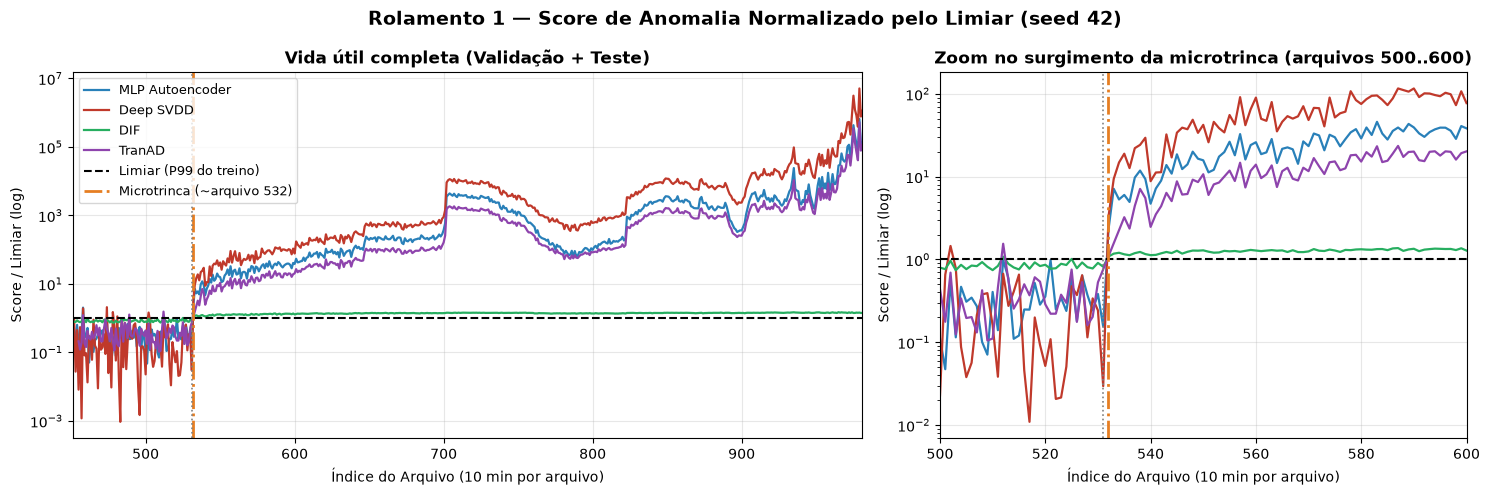

In [9]:
CORES = {"MLP Autoencoder": "#2980b9", "Deep SVDD": "#c0392b", "DIF": "#27ae60", "TranAD": "#8e44ad"}
SEED_PLOT = 42

def score_normalizado(nome, seed=SEED_PLOT):
    d = scores_modelos[(nome, seed)]
    limiar = np.percentile(d["train"], 99)
    idx = np.concatenate([d["idx_val"], d["idx_test"]])
    score = np.concatenate([d["val"], d["test"]]) / limiar
    return idx, score

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})

for ax, (xmin, xmax, titulo) in zip(axes, [
    (451, 981, "Vida útil completa (Validação + Teste)"),
    (500, 600, "Zoom no surgimento da microtrinca (arquivos 500..600)"),
]):
    for nome in MODELOS:
        idx, score = score_normalizado(nome)
        mascara = (idx >= xmin) & (idx <= xmax)
        ax.plot(idx[mascara], score[mascara], color=CORES[nome], lw=1.6, label=nome)
    ax.axhline(1.0, color="black", linestyle="--", lw=1.5, label="Limiar (P99 do treino)")
    ax.axvline(532, color="#e67e22", linestyle="-.", lw=2, label="Microtrinca (~arquivo 532)")
    ax.axvline(531, color="gray", linestyle=":", lw=1.2)
    ax.set_yscale("log")
    ax.set_xlim(xmin, xmax)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Índice do Arquivo (10 min por arquivo)")
    ax.set_ylabel("Score / Limiar (log)")
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper left", fontsize=9)
plt.suptitle("Rolamento 1 — Score de Anomalia Normalizado pelo Limiar (seed 42)", fontsize=14, fontweight="bold")
plt.tight_layout()
PASTA_REPORTS.mkdir(parents=True, exist_ok=True)
plt.savefig(PASTA_REPORTS / "deepod_score_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Trade-off: Falso Alarme vs. Antecedência de Detecção e Curvas ROC

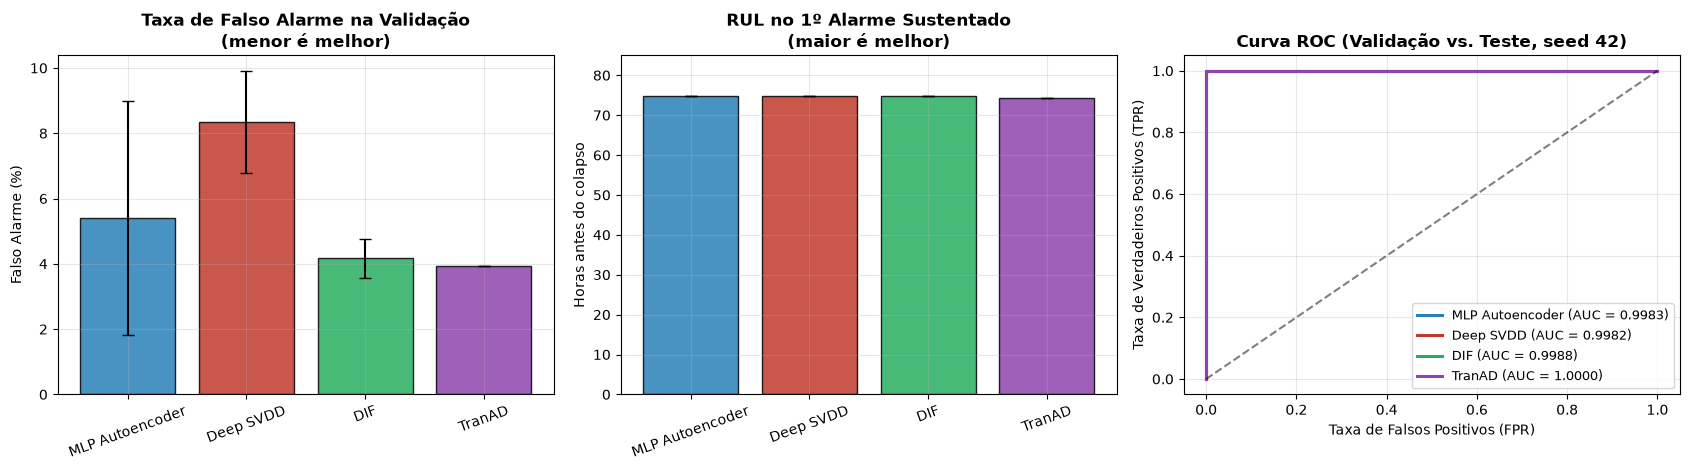

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17, 4.8))
nomes = list(MODELOS)
cores = [CORES[n] for n in nomes]

far = [df_runs[df_runs["Modelo"] == n]["falso_alarme"] * 100 for n in nomes]
axes[0].bar(nomes, [f.mean() for f in far], yerr=[f.std(ddof=0) for f in far],
            color=cores, edgecolor="black", alpha=0.85, capsize=4)
axes[0].set_title("Taxa de Falso Alarme na Validação\n(menor é melhor)", fontweight="bold")
axes[0].set_ylabel("Falso Alarme (%)")

rul = [df_runs[df_runs["Modelo"] == n]["rul_horas"] for n in nomes]
axes[1].bar(nomes, [r.mean() for r in rul], yerr=[r.std(ddof=0) for r in rul],
            color=cores, edgecolor="black", alpha=0.85, capsize=4)
axes[1].set_ylim(0, 85)
axes[1].set_title("RUL no 1º Alarme Sustentado\n(maior é melhor)", fontweight="bold")
axes[1].set_ylabel("Horas antes do colapso")

for nome in nomes:
    d = scores_modelos[(nome, SEED_PLOT)]
    y_real = np.concatenate([np.zeros(len(d["val"])), np.ones(len(d["test"]))])
    scores = np.concatenate([d["val"], d["test"]])
    fpr, tpr, _ = roc_curve(y_real, scores)
    axes[2].plot(fpr, tpr, lw=2.2, color=CORES[nome], label=f"{nome} (AUC = {roc_auc_score(y_real, scores):.4f})")
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].set_title("Curva ROC (Validação vs. Teste, seed 42)", fontweight="bold")
axes[2].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[2].set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
axes[2].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.grid(alpha=0.3)
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(PASTA_REPORTS / "deepod_benchmark_metricas.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Interpretação: Quais Variáveis Estão Fora do Regime Saudável no 1º Alarme?

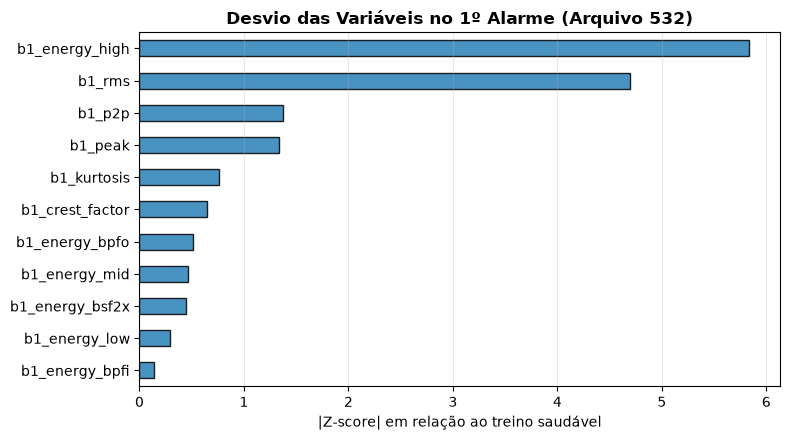

In [11]:
nome_ref = "MLP Autoencoder"
alarme_idx = int(df_runs[(df_runs["Modelo"] == nome_ref) & (df_runs["Seed"] == SEED_PLOT)]["primeiro_alarme_idx"].iloc[0])
pos_alarme = np.where(df_test["idx"].values == alarme_idx)[0][0]

z_alarme = pd.Series(np.abs(X_test[pos_alarme]), index=colunas_features).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
z_alarme.plot(kind="barh", color="#2980b9", edgecolor="black", alpha=0.85)
plt.title(f"Desvio das Variáveis no 1º Alarme (Arquivo {alarme_idx})", fontweight="bold")
plt.xlabel("|Z-score| em relação ao treino saudável")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Salvando os Scores e a Tabela Comparativa

In [ ]:
PASTA_MODELS.mkdir(parents=True, exist_ok=True)

df_scores = df_test[["idx", "filename", "timestamp"]].copy()
for nome in MODELOS:
    d = scores_modelos[(nome, SEED_PLOT)]
    chave = nome.lower().replace(" ", "_")
    serie = pd.Series(d["test"], index=d["idx_test"])
    df_scores[f"score_{chave}"] = df_scores["idx"].map(serie)
    df_scores[f"limiar_{chave}"] = np.percentile(d["train"], 99)

df_scores.to_csv(PASTA_MODELS / "scores_teste_seed42.csv", index=False)
df_runs.to_csv(PASTA_MODELS / "metricas_por_seed.csv", index=False)
df_tabela.to_csv(PASTA_MODELS / "tabela_comparativa.csv")

print("Scores e métricas salvos com sucesso em notebooks/models/deepod_benchmark/:")
display(df_scores.head())

Scores e métricas salvos com sucesso em notebooks/models/deepod_benchmark/:


,idx,filename,timestamp,score_mlp_autoencoder,limiar_mlp_autoencoder,score_deep_svdd,limiar_deep_svdd,score_dif,limiar_dif,score_tranad,limiar_tranad
531,531,2004.02.16.03.02.39,2004-02-16 03:02:39,0.107728,0.697712,0.000241,0.008182,0.234602,0.287285,NaN,1.931059
532,532,2004.02.16.03.12.39,2004-02-16 03:12:39,1.602282,0.697712,0.026872,0.008182,0.311573,0.287285,NaN,1.931059
533,533,2004.02.16.03.22.39,2004-02-16 03:22:39,4.978455,0.697712,0.077056,0.008182,0.337696,0.287285,NaN,1.931059
534,534,2004.02.16.03.32.39,2004-02-16 03:32:39,3.702405,0.697712,0.121392,0.008182,0.346175,0.287285,NaN,1.931059
535,535,2004.02.16.03.42.39,2004-02-16 03:42:39,4.199556,0.697712,0.154962,0.008182,0.331540,0.287285,6.252568,1.931059
